# Data overview

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the project's src/ package importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing.load_data import HOUR_COLUMNS, RAW_DIR, load_all, read_raw, read_stated_year

FACTORIES = ["A", "B", "C", "D"]
COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a", "D": "#eda100"}  # fixed per factory
MUTED = "#a3a29c"      # reference / comparison series
INK = "#0b0b0b"
INK_2 = "#52514e"
PROBLEM_FILL = "#e3e2dc"  # shading for problem periods
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
SV_WEEKDAYS = ["måndag", "tisdag", "onsdag", "torsdag", "fredag", "lördag", "söndag"]

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_2,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e8e7e1",
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
    "font.size": 9,
})

hourly = load_all()  # long format: timestamp, factory, kwh
series = {f: g.set_index("timestamp")["kwh"] for f, g in hourly.groupby("factory")}
daily = {f: s.resample("D").mean() for f, s in series.items()}
raw = {f: read_raw(RAW_DIR / f"Data_{f}.csv") for f in FACTORIES}
stated_year = {f: read_stated_year(RAW_DIR / f"Data_{f}.csv") for f in FACTORIES}

def shade(ax, start, end, label=None):
    """Shade a problem period on a time axis."""
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=PROBLEM_FILL, zorder=0, lw=0)
    if label:
        ax.text(pd.Timestamp(start), ax.get_ylim()[1], " " + label, va="top", ha="left",
                color=INK_2, fontsize=8)

## 0. Overview of the four series


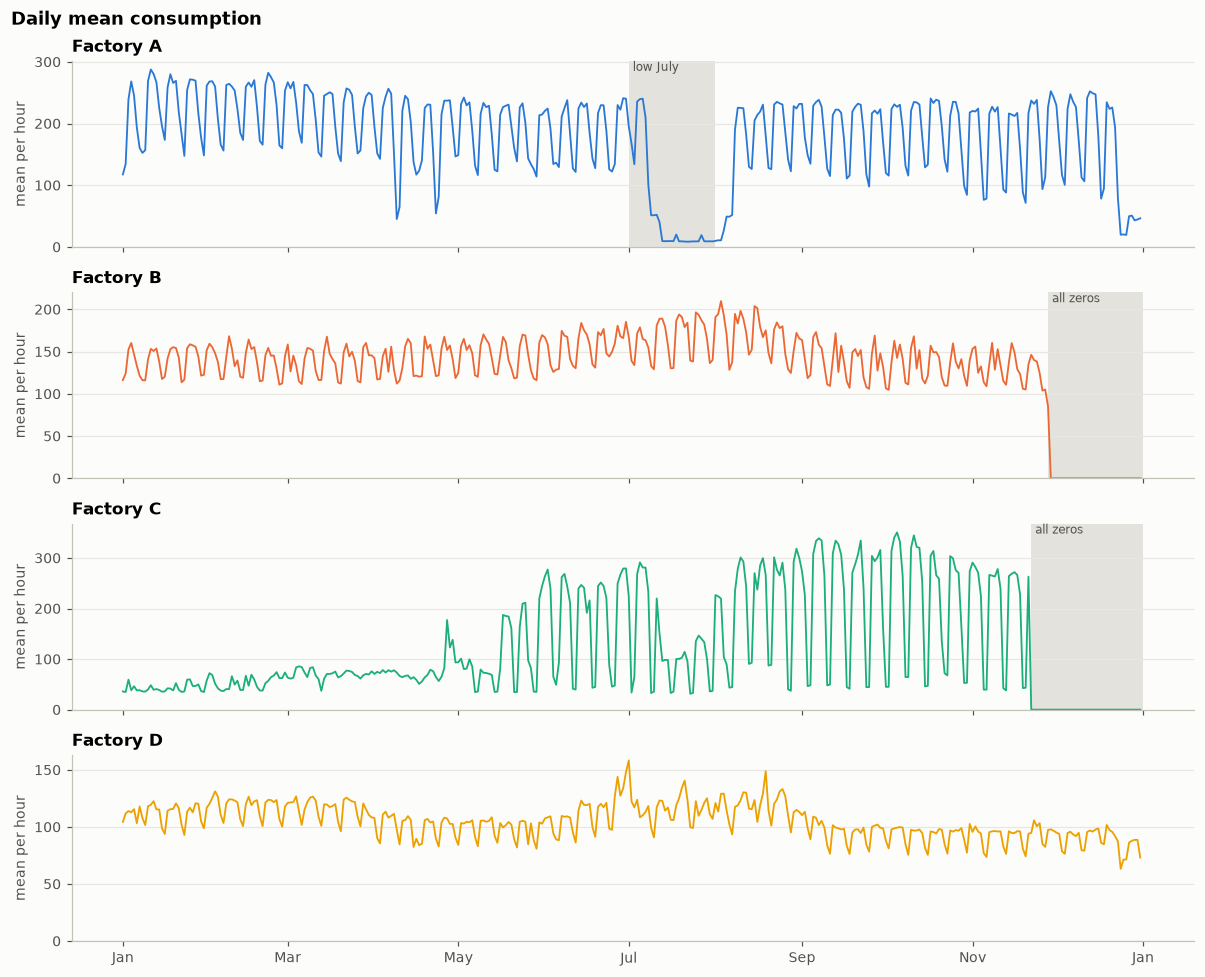

In [2]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, f in zip(axes, FACTORIES):
    ax.plot(daily[f].index, daily[f].values, color=COLORS[f], lw=1.2)
    ax.set_title(f"Factory {f}")
    ax.set_ylabel("mean per hour")
    ax.set_ylim(bottom=0)
shade(axes[1], "2022-11-28", "2023-01-01", "all zeros")
shade(axes[2], "2022-11-22", "2023-01-01", "all zeros")
shade(axes[0], "2022-07-01", "2022-08-01", "low July")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.suptitle("Daily mean consumption", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()

## 1. Which year is the data from? (Factories A, B and D)

The file headers say **2024** for A, B and D and **2022** for C.
If the dates and weekday names written in the files are taken at face value,
factories A, B and D use the least energy on **Monday and Tuesday** and run at full load on
Saturday. That is unlikely for a factory.

If the same rows are instead read as consecutive days starting on **Saturday 2022-01-01**,
the low days become **Saturday and Sunday** for every factory, matching factory C,
whose header already says 2022.

/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/1430188905.py:9: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  as_2022 = day_mean.groupby(dates_2022.weekday).mean()
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/1430188905.py:9: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  as_2022 = day_mean.groupby(dates_2022.weekday).mean()
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/1430188905.py:9: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  as_2022 = day_mean.groupby(dates_2022.weekday).mean()
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/1430188905.py:9: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeInd

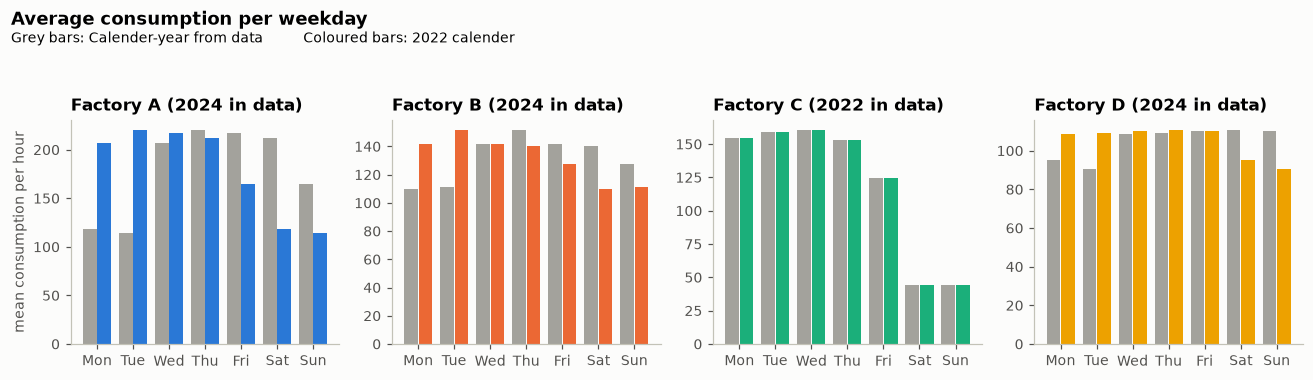

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=False)
x = np.arange(7)
w = 0.38
for ax, f in zip(axes, FACTORIES):
    r = raw[f]
    day_mean = r[HOUR_COLUMNS].mean(axis=1)
    as_labeled = day_mean.groupby(r["Veckodag"].map(SV_WEEKDAYS.index)).mean()
    dates_2022 = pd.date_range("2022-01-01", periods=len(r), freq="D")
    as_2022 = day_mean.groupby(dates_2022.weekday).mean()
    ax.bar(x - w / 2 - 0.01, as_labeled.reindex(range(7)), w, color=MUTED)
    ax.bar(x + w / 2 + 0.01, as_2022.reindex(range(7)), w, color=COLORS[f])
    ax.set_xticks(x, WEEKDAYS)
    ax.set_title(f"Factory {f} ({stated_year[f]} in data)")
    ax.yaxis.grid(False)
axes[0].set_ylabel("mean consumption per hour")
fig.suptitle("Average consumption per weekday", x=0.01, y=1.06, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.97, "Grey bars: Calender-year from data"
         "          Coloured bars: 2022 calender", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.95))

### More evidence: public holidays

On a public holiday a factory should use less energy than on a normal day of the same weekday.
The chart below compares each Swedish public holiday with the median of the same weekday in
the three weeks before and after it. The x-axis is the mean consumption per hour on that day.
Only weekday holidays whose position differs between 2022 and 2024 are used. Fixed-date holidays like
New Year's Day fall on the same row in both readings, so they cannot tell the years apart.

* **Grey:** the holidays of the year written in the file header (2024), looked up using the dates in the file.
* **Factory colour:** the 2022 holidays, using dates counted from 2022-01-01.
* **Filled dot:** the holiday. **Ring:** a normal day of the same weekday. The line between them shows how much lower the holiday is.

The 2022 holidays are clearly below normal in all three factories.
The 2024 holidays mostly look like normal working days.

/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/11996398.py:16: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  same_wd = window[(window.index.weekday == h.weekday()) & (window.index != h)]
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/11996398.py:16: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  same_wd = window[(window.index.weekday == h.weekday()) & (window.index != h)]
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/11996398.py:16: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  same_wd = window[(window.index.weekday == h.weekday()) & (window.index != h)]
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/11996398.py:16: Pandas4Warning: DatetimeIndex.weekday is

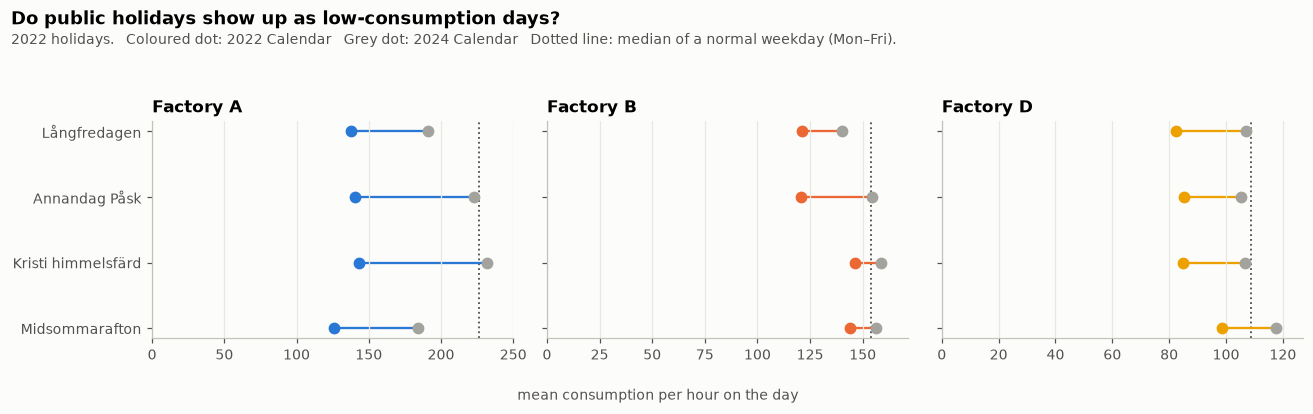

In [4]:
HOLIDAYS = {
    2022: {"Långfredagen": "04-15", "Annandag Påsk": "04-18",
            "Kristi himmelsfärd": "05-26", "Midsommarafton": "06-24",},
    2024: {"Långfredagen": "03-29", "Annandag Påsk": "04-01",
            "Kristi himmelsfärd": "05-09", "Midsommarafton": "06-21",},
}

def holiday_usage(day_mean: pd.Series, year: int) -> pd.DataFrame:
    """Holiday consumption and median of the same weekday within +-21 days (excluding the holiday)."""
    out = {}
    for name, md_ in HOLIDAYS[year].items():
        h = pd.Timestamp(f"{year}-{md_}")
        if h not in day_mean.index or pd.isna(day_mean[h]):
            continue
        window = day_mean[h - pd.Timedelta(days=21): h + pd.Timedelta(days=21)]
        same_wd = window[(window.index.weekday == h.weekday()) & (window.index != h)]
        out[name] = {"holiday": day_mean[h], "normal": same_wd.median()}
    return pd.DataFrame(out).T

check = ["A", "B", "D"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
names = ["Långfredagen", "Annandag Påsk", "Kristi himmelsfärd", "Midsommarafton"]
y = np.arange(len(names))
for ax, f in zip(axes, check):
    r = raw[f]
    day_mean = r[HOUR_COLUMNS].mean(axis=1)
    as_2022 = pd.Series(day_mean.values, index=pd.date_range("2022-01-01", periods=len(r)))
    usage = holiday_usage(as_2022, 2022).reindex(names)
    xmax = usage.max().max()
    ax.hlines(y, usage["holiday"], usage["normal"], color=COLORS[f], lw=1.5, zorder=1)
    ax.scatter(usage["normal"], y, s=45, color=MUTED, zorder=2)
    ax.scatter(usage["holiday"], y, s=45, color=COLORS[f], zorder=3)
    # Median of a normal weekday: Mon-Fri (2022 dates), excluding the holidays above and empty/all-zero days
    hol_2022 = [pd.Timestamp(f"2022-{md_}") for md_ in HOLIDAYS[2022].values()]
    normal = as_2022[(as_2022.index.weekday < 5) & ~as_2022.index.isin(hol_2022) & (as_2022 > 0)]
    ax.axvline(normal.median(), color=INK_2, lw=1.2, ls=":", zorder=0)
    xmax = max(xmax, normal.median())
    ax.set_title(f"Factory {f}")
    ax.set_xlim(0, xmax * 1.08)
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, names)
axes[0].invert_yaxis()
fig.suptitle("Do public holidays show up as low-consumption days?", x=0.01, y=1.06, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.01, 0.97, "2022 holidays.   Coloured dot: 2022 Calendar   Grey dot: 2024 Calendar   "
         "Dotted line: median of a normal weekday (Mon–Fri).", color=INK_2, fontsize=9)
fig.supxlabel("mean consumption per hour on the day", color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.95))

In [5]:
rows = []
for f in FACTORIES:
    r = raw[f]
    empty = r[HOUR_COLUMNS].isna().all(axis=1)
    rows.append({
        "factory": f,
        "header year": stated_year[f],
        "day rows": len(r),
        "first row (as written)": f"{int(r['Dag'].iloc[0])} {r['Månad'].iloc[0]}, {r['Veckodag'].iloc[0]}",
        "empty day rows": ", ".join(f"{int(d)} {m}" for d, m in zip(r.loc[empty, "Dag"], r.loc[empty, "Månad"])) or "none",
        "days with data": int((~empty).sum()),
    })
pd.DataFrame(rows).set_index("factory")

,header year,day rows,first row (as written),empty day rows,days with data
factory,,,,,
A,2024,366,"1 januari, måndag",31 december,365
B,2024,366,"1 januari, måndag",31 december,365
C,2022,365,"1 januari, lördag",none,365
D,2024,366,"1 januari, måndag",31 december,365


> **Question 1:** Are factories A, B and D really from **2022** (or another year that starts on a
> Saturday), and not 2024 as the file header says? Which calendar year is each file from?
> Are all four factories from the **same period**?

## 2. Data ends abruptly at the end of the year (Factories B and C)

* **Factory B** is exactly **0** from **2022-11-28 14:00** to the end of the year (802 hours, 33+ days).
  It drops from about 180 to 0 from one hour to the next, with no ramp-down.
* **Factory C** is exactly **0** from **2022-11-22 00:00** to the end of the year (960 hours, 40 days).

A real shutdown usually still shows some base load (lighting, ventilation, servers). An exact
zero for weeks looks more like a **meter or data-export problem**.

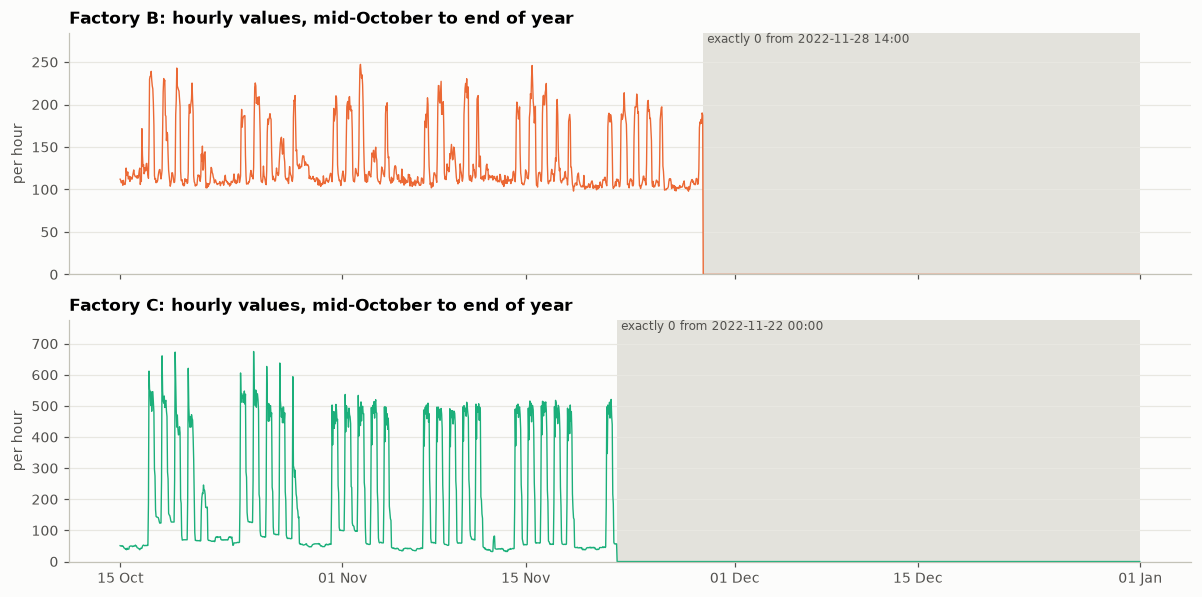

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, f, start in zip(axes, ["B", "C"], ["2022-11-28 14:00", "2022-11-22 00:00"]):
    s = series[f]["2022-10-15":]
    ax.plot(s.index, s.values, color=COLORS[f], lw=0.9)
    ax.set_ylim(0, s.max() * 1.15)
    shade(ax, start, "2023-01-01", f"exactly 0 from {start}")
    ax.set_title(f"Factory {f}: hourly values, mid-October to end of year")
    ax.set_ylabel("per hour")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.tight_layout()

> **Question 2:** What happened at factory **B from 28 November** and factory **C from 22 November**?
> Was the factory really shut down (and does it truly use *zero* energy), or is the data missing?
> If missing, can the real values be provided?

## 3. Factory A: zero values in April and a very low July

**Zeros in April.** Factory A has five isolated zero values, all on Saturday mornings:
2022-04-09 08:00–10:00 and 2022-04-23 08:00–11:00. The hours around them are normal,
which looks like a measurement gap rather than a real stop.

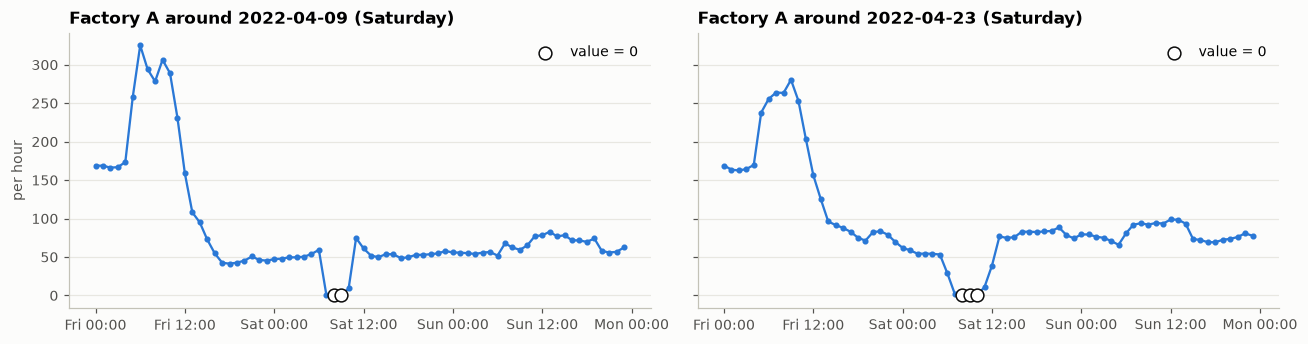

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, day in zip(axes, ["2022-04-09", "2022-04-23"]):
    d = pd.Timestamp(day)
    s = series["A"][d - pd.Timedelta(days=1): d + pd.Timedelta(days=2) - pd.Timedelta(hours=1)]
    ax.plot(s.index, s.values, color=COLORS["A"], marker="o", ms=3)
    zeros = s[s == 0]
    ax.scatter(zeros.index, zeros.values, s=70, facecolor="white", edgecolor=INK, zorder=3, label="value = 0")
    ax.set_title(f"Factory A around {day} ({d.day_name()})")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %H:%M"))
    ax.legend(loc="upper right")
axes[0].set_ylabel("per hour")
fig.tight_layout()

**July.** In July factory A runs at about a third of its normal level (monthly mean about 62
against about 190 in June and August). That fits a summer shutdown, which is common in Sweden,
but it is worth confirming. The model needs to know whether this happens every year.

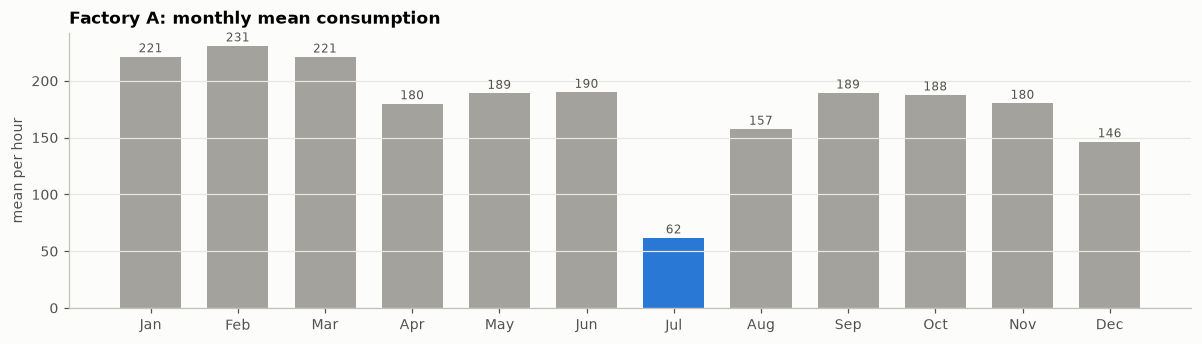

In [8]:
monthly = pd.DataFrame({f: series[f].resample("MS").mean() for f in FACTORIES})
monthly.index = monthly.index.strftime("%b")

fig, ax = plt.subplots(figsize=(11, 3.2))
x = np.arange(12)
ax.bar(x, monthly["A"], color=[MUTED if m != "Jul" else COLORS["A"] for m in monthly.index], width=0.7)
for i, v in enumerate(monthly["A"]):
    ax.text(i, v + 4, f"{v:.0f}", ha="center", color=INK_2, fontsize=8)
ax.set_xticks(x, monthly.index)
ax.set_ylabel("mean per hour")
ax.set_title("Factory A: monthly mean consumption")
fig.tight_layout()

> **Question 3a:** Are the zero values for factory A on **9 April 08–10** and **23 April 08–11**
> real (power cut, maintenance) or missing measurements?
>
> **Question 3b:** Was factory A on **summer shutdown in July**? Does this happen every year, and in
> which weeks? Are there other planned shutdowns we should know about (Christmas, other holidays)?

## 4. Factory C: large change in level during the year, and high peaks

Factory C goes from about **43 per hour in January** to **over 200 per hour in August–October**,
about five times as much. Single hours reach up to **790** (2022-06-27 06:00). The other
factories stay at about the same level all year.

The model will be wrong if this growth is caused by something it cannot see, like new
equipment, a new production line or a change in what the meter measures.

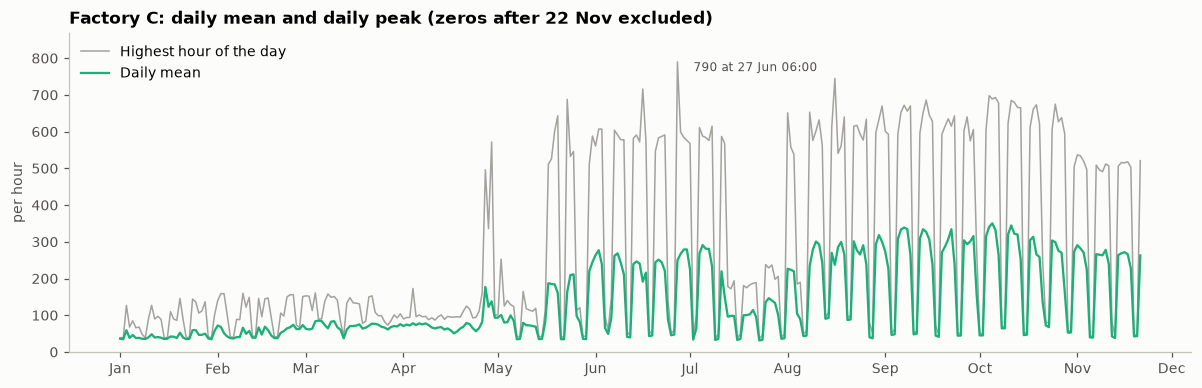

In [9]:
c = series["C"][:"2022-11-21"]
c_daily = c.resample("D").agg(["mean", "max"])

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(c_daily.index, c_daily["max"], color=MUTED, lw=1, label="Highest hour of the day")
ax.plot(c_daily.index, c_daily["mean"], color=COLORS["C"], lw=1.5, label="Daily mean")
top = c.idxmax()
ax.annotate(f"{c.max():.0f} at {top:%d %b %H:%M}", xy=(top, c.max()), xytext=(10, -4),
            textcoords="offset points", color=INK_2, fontsize=8, va="center")
ax.set_ylim(0, c.max() * 1.1)
ax.set_ylabel("per hour")
ax.set_title("Factory C: daily mean and daily peak (zeros after 22 Nov excluded)")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper left")
fig.tight_layout()

## 5. Time zone and daylight saving time

Every day in every file has exactly 24 values, including **27 March 2022** (clocks go forward,
a 23-hour day) and **30 October 2022** (clocks go back, a 25-hour day). So the data is either in
a fixed time without daylight saving, or the extra/missing hour was adjusted somehow.

The charts compare the average weekday profile in the two weeks **before** and **after**
the spring change. In factories **A, B and C** the morning ramp-up appears **one hour earlier**
after the change (D ramps up slowly, so it is harder to see). In late October the ramp-up moves
one hour later again in A, B and D. That is what we would see if the timestamps were in
**fixed winter time (UTC+1)** while the staff follow the local clock.

/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/404513967.py:3: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  x = x[x.index.weekday < 5]
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/404513967.py:3: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  x = x[x.index.weekday < 5]
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/404513967.py:3: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  x = x[x.index.weekday < 5]
/var/folders/mv/c3wb1brd7tb_qwf9rhf007vc0000gn/T/ipykernel_44941/404513967.py:3: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  x = x[x.index.weekday < 5]
/var/folders/mv/c3wb1brd7tb_qwf9

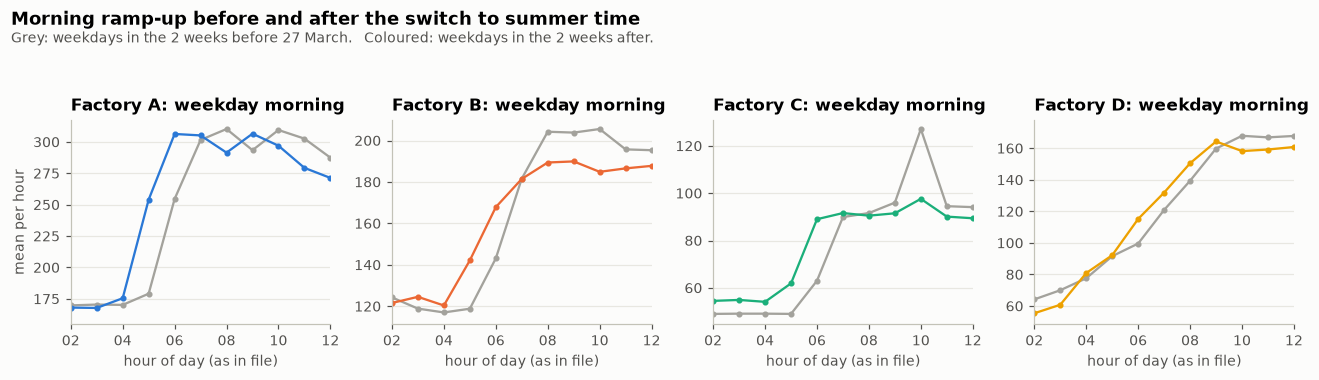

In [10]:
def weekday_profile(s, start, end):
    x = s[start:end]
    x = x[x.index.weekday < 5]
    return x.groupby(x.index.hour).mean()

change = pd.Timestamp("2022-03-27")
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, f in zip(axes, FACTORIES):
    s = series[f]
    before = weekday_profile(s, change - pd.Timedelta(days=14), change - pd.Timedelta(hours=1))
    after = weekday_profile(s, change + pd.Timedelta(days=1), change + pd.Timedelta(days=15))
    ax.plot(before.index, before.values, color=MUTED, marker="o", ms=3)
    ax.plot(after.index, after.values, color=COLORS[f], marker="o", ms=3)
    ax.set_xlim(2, 12)
    ax.set_xticks(range(2, 13, 2), [f"{h:02d}" for h in range(2, 13, 2)])
    ax.set_xlabel("hour of day (as in file)")
    ax.set_title(f"Factory {f}: weekday morning")
axes[0].set_ylabel("mean per hour")
fig.suptitle("Morning ramp-up before and after the switch to summer time", x=0.01, y=1.06, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.01, 0.97, "Grey: weekdays in the 2 weeks before 27 March.   "
         "Coloured: weekdays in the 2 weeks after.", color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.95))

> **Question 5:** Which time zone are the timestamps in: local Swedish time (CET/CEST) or
> fixed winter time / UTC+1? How were the 23-hour day (27 March) and the 25-hour day
> (30 October) handled? Does column `00-01` mean the energy used **between** 00:00 and 01:00?

## 6. Units, number format and file differences

The four files were not exported the same way:

In [11]:
rows = []
for f in FACTORIES:
    path = RAW_DIR / f"Data_{f}.csv"
    first_line = path.read_text(encoding="utf-8-sig").splitlines()[0]
    sep = ";" if first_line.count(";") > first_line.count(",") else ","
    s = series[f]
    nz = s[s > 0]
    decimals = nz.map(lambda v: len(f"{v:.6f}".rstrip("0").split(".")[1])).max()
    rows.append({
        "factory": f,
        "Företag (header)": first_line.split(sep)[1] or "(empty)",
        "separator": sep,
        "decimal mark": "," if sep == ";" else ".",
        "max decimals": int(decimals),
        "whole numbers (%)": round(100 * (nz == nz.round()).mean(), 1),
        "min": s.min(), "median": s.median(), "max": s.max(),
    })
pd.DataFrame(rows).set_index("factory")

,Företag (header),separator,decimal mark,max decimals,whole numbers (%),min,median,max
factory,,,,,,,,
A,(empty),;,",",2,2.0,0.0,170.680,374.120
B,B,",",.,3,0.9,0.0,124.656,300.128
C,Testföretag,;,",",0,100.0,0.0,54.000,790.000
D,Testföretag,;,",",0,100.0,40.0,98.000,256.000


* Factories **C and D** contain only **whole numbers**, while A and B have 2–3 decimals.
  If C and D are rounded, small changes are lost.
* Factory **B** uses a different file format (comma separator, decimal point) and a different
  number of decimals (multiples of 0.016), which suggests a different meter or export system.
* No file states the **unit**. We assume kWh per hour (i.e. average kW), but it could be another
  unit or a scaled value.

> **Question 6:** What is the **unit** of the values (kWh per hour, kW, MWh…)?
> Are factory C and D values **rounded** to whole numbers? Is each value the total for the factory
> (one main meter), or a sum or a part of several meters? Do the files come from different
> measurement systems?

## Summary: questions for the data supplier

| # | Topic | Question |
|---|-------|----------|
| 1 | Year | The headers of A, B and D say 2024, but the weekday pattern, the holidays and the empty 31 Dec row all point to **2022**. Which year is each file from? Are all four from the same period? |
| 2 | Missing data | B is exactly 0 from 28 Nov 14:00, C from 22 Nov. Real shutdown or missing data? Can the real values be provided? |
| 3a | Factory A | Zeros on 9 Apr 08–10 and 23 Apr 08–11: real or missing measurements? |
| 3b | Factory A | Is the low July a summer shutdown? Every year? Other planned shutdowns? |
| 4 | Factory C | Why does consumption grow ~5× from January to autumn? Are peaks up to 790 realistic? |
| 5 | Time | Local time or fixed UTC+1? How were the DST days handled? Does `00-01` mean energy used between 00:00 and 01:00? |
| 6 | Units | What is the unit? Are C and D rounded? One main meter per factory or several? |

**Helpful extra information, if available:** more years of data (ideally 2–3 years per factory),
the factories' locations (to add weather data), and production schedules or shutdown calendars.